![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `scikit-learn` (`sklearn`): os modelos `LinearRegression`, `KNeighborsRegressor` e `RandomForestRegressor`, o `PolynomialFeatures`, o `StandardScaler`, o `make_pipeline` e a `permutation_importance`
* `xgboost`: o modelo `XGBRegressor` (Gradient Boosting)
* `statsmodels`: a decomposição (`seasonal_decompose`) e o modelo estatístico (SARIMA) para comparação

`PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

## 📌 1 - Regressão sobre o tempo

O ARIMA segue a **tendência** e o SARIMA acrescenta o **ciclo sazonal**, deixando o **resíduo** como ruído. Agora a previsão será feita com **Machine Learning**. A primeira ideia é ajustar uma **regressão** aos pontos, como em qualquer curva: o valor em função do tempo, $y = f(t)$. Vale entender por que a série pede um tratamento próprio.

> **Dataset:** o **aluguel de bicicletas** do Capital Bikeshare, em Washington D.C.: o número de aluguéis (`cnt`) em cada hora de 2011 e 2012. É o mesmo conjunto até o fim da aula. A previsão pedida: os **aluguéis da próxima hora**.

### 1.1 - Preparando a série

Lemos o arquivo com os argumentos de sempre. A data (`dteday`) e a hora (`hr`, de 0 a 23) estão em colunas separadas, então somamos as duas para formar o índice de tempo:

In [2]:
df = pd.read_csv(
    PATH + 'datasets/bike_sharing_horario.csv',
    parse_dates=['dteday'],
)
df.index = df['dteday'] + pd.to_timedelta(df['hr'], unit='h')

print('Linhas:', len(df), '| de', df.index[0], 'até', df.index[-1])

Linhas: 17379 | de 2011-01-01 00:00:00 até 2012-12-31 23:00:00


In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


O dataset **puro**: o total de aluguéis a cada hora, nos dois anos:

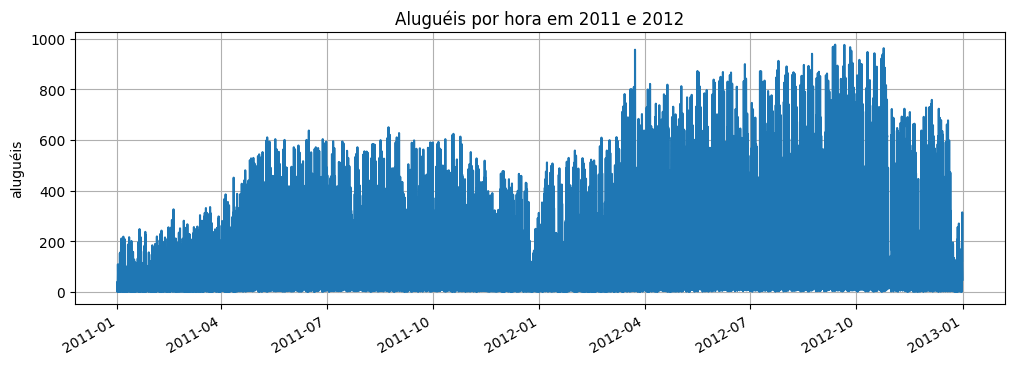

In [4]:
df['cnt'].plot(figsize=(12, 4), title='Aluguéis por hora em 2011 e 2012', ylabel='aluguéis', grid=True)
plt.show()

No gráfico vemos: o aluguel é mais alto no verão que no inverno e **cresce de 2011 para 2012**. O arquivo só tem as horas com registro. Com `asfreq('h')`, a série passa a ter **uma linha por hora**, e as horas que faltavam aparecem como `NaN`:

In [5]:
horaria = df['cnt'].asfreq('h')

print('Número de horas:', len(horaria))
print('Horas sem valor:', horaria.isna().sum())

Número de horas: 17544
Horas sem valor: 165


Um modelo de ML não aceita `NaN` nos atributos. Com `.ffill()` (*forward fill*), cada hora ausente recebe o valor da hora anterior. Usamos só o passado, como na hora de prever:

In [6]:
print('Horas sem valor antes do preenchimento:', horaria.isna().sum())

Horas sem valor antes do preenchimento: 165


In [7]:
horaria = horaria.ffill()
print('Horas sem valor depois do preenchimento:', horaria.isna().sum())

Horas sem valor depois do preenchimento: 0


### 1.2 - Série diária

Para ver a tendência e o ciclo do ano, somamos os aluguéis de cada dia com `resample('D').sum()`. Os dias até 31/08/2012 são o treino, e os de setembro a dezembro de 2012, o teste:

In [8]:
diaria = horaria.resample('D').sum()
treino_d = diaria.loc[:'2012-08-31']
teste_d = diaria.loc['2012-09-01':]

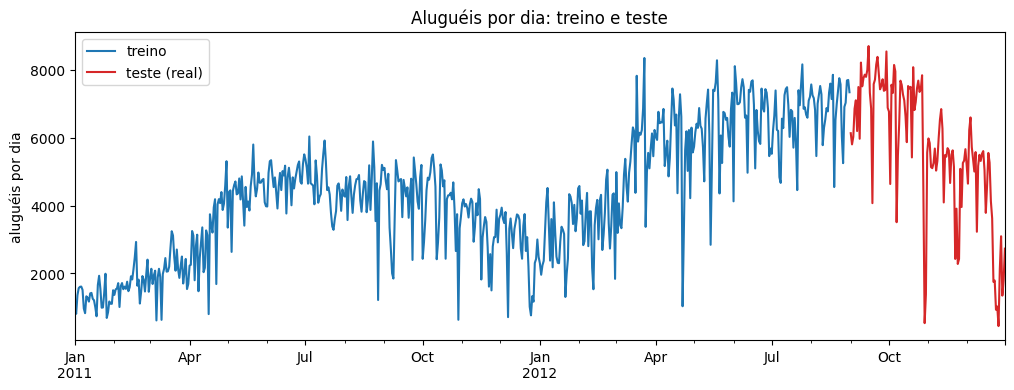

In [9]:
ax = treino_d.plot(figsize=(12, 4), label='treino', ylabel='aluguéis por dia', grid=True, title='Aluguéis por dia: treino e teste')
teste_d.plot(ax=ax, color='tab:red', label='teste (real)')
ax.legend()
plt.show()

### 1.3 - Regressão polinomial

Uma regressão **polinomial** ajusta uma curva $y = f(t)$ com grau maior que 1: o `PolynomialFeatures` cria as colunas $t, t^2, t^3, \dots$ e a `LinearRegression` ajusta os pesos. O tempo $t$ é o número do dia, reescalado para o intervalo de -1 a 1 (com os valores em bruto, os graus altos ficam instáveis). Ajustamos só no treino, com os graus 3, 9, 12 e 15. A função `ajustar_polinomio` faz o ajuste, e a função `plotar_graus` desenha a série e cada curva em um painel, com uma linha tracejada separando o treino do teste:

In [10]:
graus = [3, 9, 12, 15]

In [11]:
def ajustar_polinomio(serie, grau):
    t = np.arange(len(serie))
    x = 2 * t / (len(t) - 1) - 1

    colunas = PolynomialFeatures(grau).fit_transform(x.reshape(-1, 1))
    corte = len(serie.loc[:'2012-08-31'])

    modelo = LinearRegression().fit(colunas[:corte], serie.values[:corte])
    return pd.Series(modelo.predict(colunas), index=serie.index)

curvas = {grau: ajustar_polinomio(diaria, grau) for grau in graus}

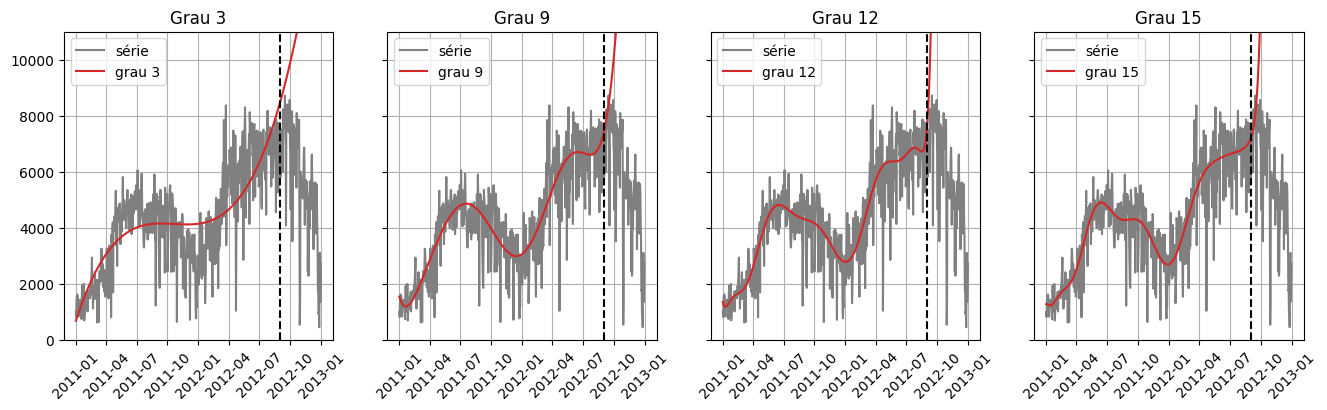

In [12]:
def plotar_graus(serie, curvas, limites):
    fig, eixos = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    for eixo, (grau, curva) in zip(eixos, curvas.items()):
        eixo.plot(serie, color='gray', label='série')
        eixo.plot(curva, color='tab:red', label=f'grau {grau}')
        eixo.axvline(pd.Timestamp('2012-09-01'), color='black', linestyle='--')
        eixo.set_title(f'Grau {grau}')
        eixo.set_ylim(limites)
        eixo.tick_params(axis='x', labelrotation=45)
        eixo.grid(True)
        eixo.legend()
    plt.show()

plotar_graus(diaria, curvas, (0, 11000))

No gráfico vemos: o grau 3 acompanha a alta de 2011 para 2012, mas **perde o ciclo** e sobe sem parar no teste. Com os graus 9, 12 e 15, a curva acompanha cada vez melhor o treino e **diverge no teste**: quanto maior o grau, mais depressa ela sai do gráfico. O modelo decora o treino e erra o futuro.

### 1.4 - Regressão sobre o resíduo

Removemos a **tendência** e a **sazonalidade** e analisamos o **resíduo**: $R_t = x_t - T_t - S_t$. A função `seasonal_decompose` estima os componentes (modelo aditivo, com o ciclo de 7 dias, o da semana). O resíduo fica em `.resid`. As pontas da tendência não existem, então tiramos as linhas vazias com `.dropna()`. O gráfico mostra os quatro componentes:

In [13]:
decomposicao = seasonal_decompose(diaria, model='additive', period=7)

residuo = decomposicao.resid.dropna()

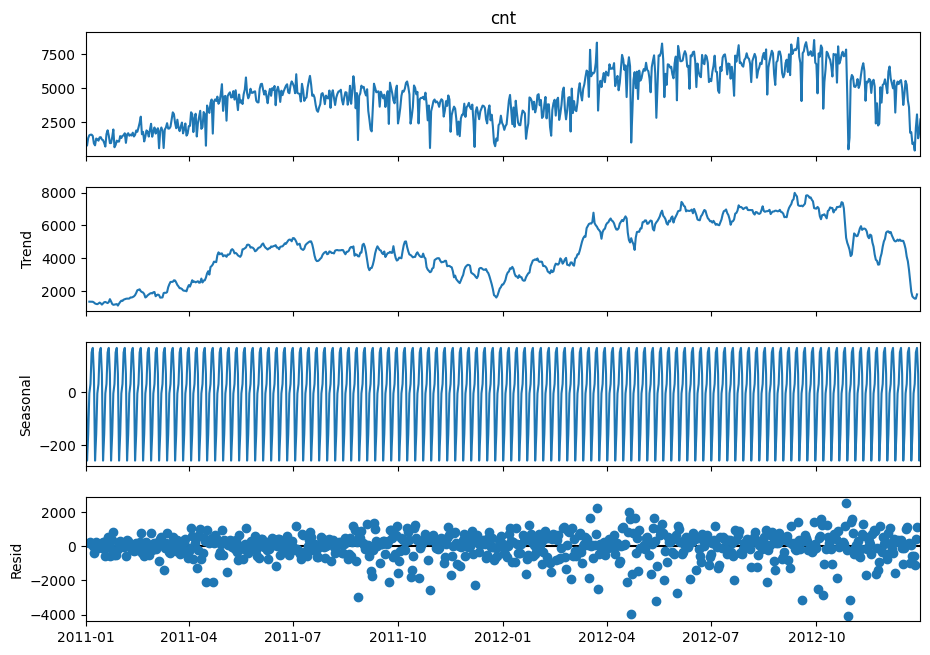

In [14]:
fig = decomposicao.plot()
fig.set_size_inches(10, 7)
plt.show()

A mesma regressão polinomial, com os mesmos graus, agora sobre o resíduo:

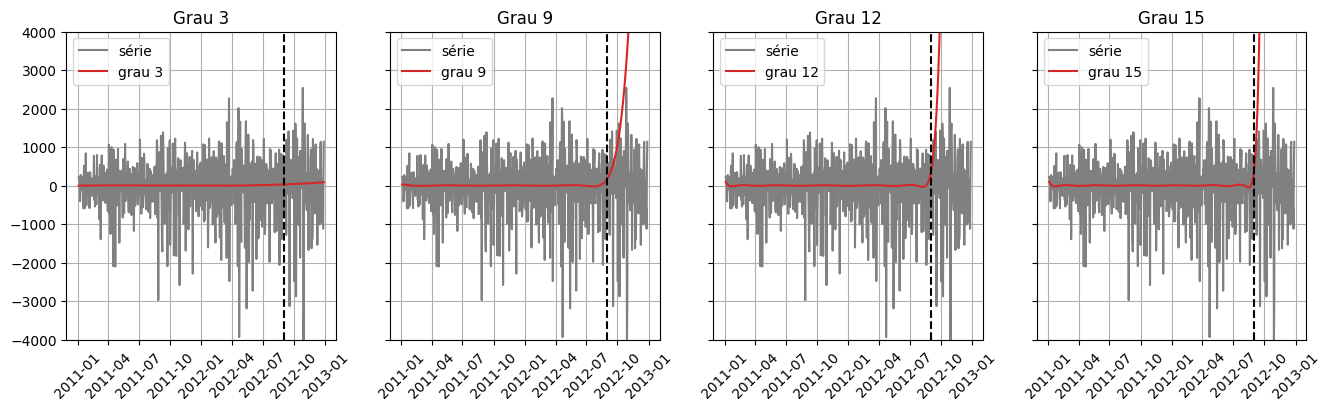

In [15]:
curvas_res = {grau: ajustar_polinomio(residuo, grau) for grau in graus}

plotar_graus(residuo, curvas_res, (-4000, 4000))

No gráfico vemos: nenhum grau captura o resíduo. As curvas ficam coladas em zero no treino, porque sem tendência nem ciclo o resíduo não depende do tempo, e os graus 9, 12 e 15 **divergem** no teste, quanto maior o grau, mais depressa. A regressão sobre o tempo conhece apenas a **posição no tempo**, o $t$ de cada ponto. O que aconteceu **antes** do ponto fica fora do modelo, e o valor de hoje se parece com o de ontem (tópico 2). A decomposição usa a série inteira, inclusive o período de teste, então serve só para demonstrar o comportamento, e não como avaliação de previsão.

## 📌 2 - Série como tabela

No Machine Learning tradicional, **x parecido, y parecido**: dá para prever o y de um x novo. Na série temporal, o tempo é uma **data arbitrária**: trocar as datas não muda a série, e a data não carrega informação sobre o valor. A informação está nos **valores vizinhos**.

Os modelos esperam uma **tabela**: cada linha é um exemplo, com **atributos** (`X`) e um **alvo** (`y`). Uma série temporal é uma única coluna. Neste tópico, transformamos a série em uma tabela, e o tempo entra pelos atributos.

### 2.1 - Janela de valores passados

Primeiro, um exemplo **pequeno**, feito à mão: oito valores de produção diária.

In [16]:
pequena = pd.Series(
    [10, 12, 11, 13, 15, 14, 16, 18],
    index=pd.date_range('2012-01-01', periods=8, freq='D'),
    name='x',
)
pequena

,x
2012-01-01,10
2012-01-02,12
2012-01-03,11
2012-01-04,13
2012-01-05,15
2012-01-06,14
2012-01-07,16
2012-01-08,18


Para prever o valor de um dia, usamos como **atributos** os **3 dias anteriores**. O valor do dia é o **alvo**. Com `.shift(k)`, uma coluna para cada valor passado:

In [19]:
pequena.shift(2)

,x
2012-01-01,NaN
2012-01-02,NaN
2012-01-03,10.0
2012-01-04,12.0
2012-01-05,11.0
2012-01-06,13.0
2012-01-07,15.0
2012-01-08,14.0


In [17]:
tabela_pd = pd.DataFrame({
    'x(t-3)': pequena.shift(3),
    'x(t-2)': pequena.shift(2),
    'x(t-1)': pequena.shift(1),
    'y(t)': pequena,
})

tabela_pd

,x(t-3),x(t-2),x(t-1),y(t)
2012-01-01,NaN,NaN,NaN,10
2012-01-02,NaN,NaN,10.0,12
2012-01-03,NaN,10.0,12.0,11
2012-01-04,10.0,12.0,11.0,13
2012-01-05,12.0,11.0,13.0,15
2012-01-06,11.0,13.0,15.0,14
2012-01-07,13.0,15.0,14.0,16
2012-01-08,15.0,14.0,16.0,18


As linhas com `NaN` não têm janela completa. Com `.dropna()`, elas saem, e cada linha é um exemplo: três valores passados e o valor seguinte.

In [20]:
tabela_pd = tabela_pd.dropna()
tabela_pd

,x(t-3),x(t-2),x(t-1),y(t)
2012-01-04,10.0,12.0,11.0,13
2012-01-05,12.0,11.0,13.0,15
2012-01-06,11.0,13.0,15.0,14
2012-01-07,13.0,15.0,14.0,16
2012-01-08,15.0,14.0,16.0,18


### 2.2 - Lag features

Cada coluna de valor passado é um **lag** (defasagem). O **lag 1** é o valor da hora anterior; o **lag 24**, o da mesma hora de ontem; o **lag 168**, o da mesma hora na semana passada ($24 \times 7 = 168$ horas).

Criamos o `DataFrame` `dados`, com o alvo `y` (os aluguéis), e os três lags:

In [21]:
dados = pd.DataFrame({'y': horaria})
dados.head()

,y
2011-01-01 00:00:00,16.0
2011-01-01 01:00:00,40.0
2011-01-01 02:00:00,32.0
2011-01-01 03:00:00,13.0
2011-01-01 04:00:00,1.0


In [22]:
dados['lag_1'] = horaria.shift(1)
dados['lag_24'] = horaria.shift(24)
dados['lag_168'] = horaria.shift(168)
dados.iloc[165:172]

,y,lag_1,lag_24,lag_168
2011-01-07 21:00:00,39.0,51.0,48.0,NaN
2011-01-07 22:00:00,36.0,39.0,52.0,NaN
2011-01-07 23:00:00,15.0,36.0,23.0,NaN
2011-01-08 00:00:00,25.0,15.0,17.0,16.0
2011-01-08 01:00:00,16.0,25.0,7.0,40.0
2011-01-08 02:00:00,16.0,16.0,1.0,32.0
2011-01-08 03:00:00,7.0,16.0,1.0,13.0


Os primeiros 24 valores do `lag_24` e os primeiros 168 do `lag_168` são `NaN`: no começo da série ainda não existe "ontem" nem "semana passada".

### 2.3 - Escolha dos lags

Os lags vêm do **ciclo** do problema. A série horária se repete a cada **24 horas** (o ciclo do dia) e a cada **168 horas** (o ciclo da semana: dia útil e fim de semana). Duas semanas seguidas, de segunda a domingo:

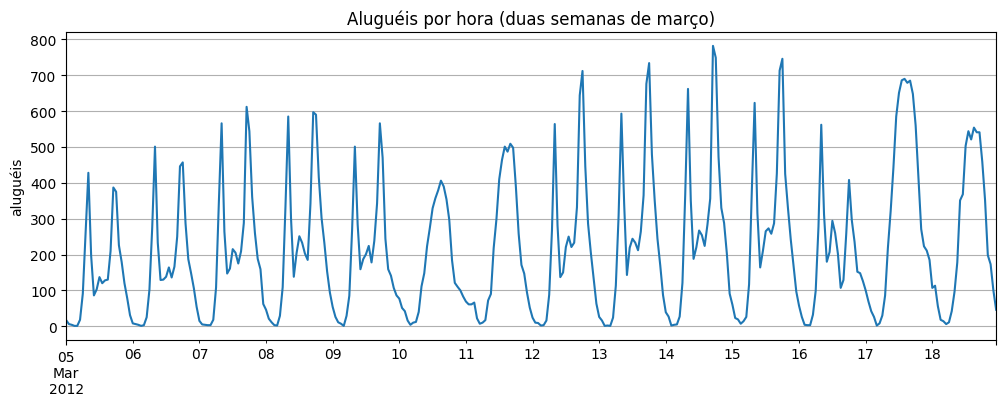

In [23]:
horaria.loc['2012-03-05':'2012-03-18'].plot(figsize=(12, 4), title='Aluguéis por hora (duas semanas de março)', ylabel='aluguéis', grid=True)
plt.show()

No gráfico vemos: nos dias úteis o aluguel tem **dois picos** por dia (de manhã e no fim da tarde, o trajeto do trabalho), e no sábado e no domingo o pico é um só, no meio do dia. Por isso usamos os lags **1** (a hora anterior), **24** (a mesma hora de ontem) e **168** (a mesma hora da semana passada): poucos lags bem escolhidos valem mais que muitos.

Para escolher os lags, medimos a correlação entre a série e ela mesma deslocada de `k` horas, para alguns candidatos. O teste são as últimas 744 horas (`horizonte`, dezembro de 2012: 31 dias vezes 24 horas). Usamos só o treino, porque o teste não pode orientar nenhuma escolha:

In [24]:
horizonte = 744

candidatos = [1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
treino_corr = horaria.iloc[:-horizonte]
correlacao = pd.Series({k: treino_corr.corr(treino_corr.shift(k)) for k in candidatos})

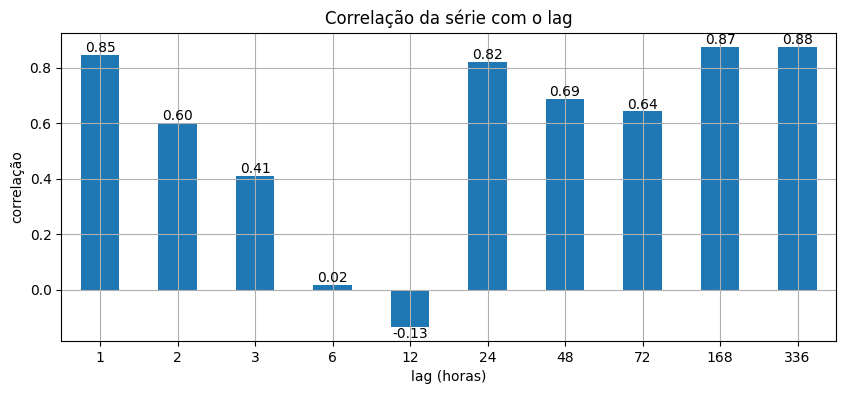

In [25]:
ax = correlacao.plot(kind='bar', figsize=(10, 4), rot=0, xlabel='lag (horas)', ylabel='correlação', grid=True, title='Correlação da série com o lag')
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.show()

No gráfico vemos: os lags **1** (0,85), **24** (0,82) e **168** (0,87) têm as maiores correlações. Os lags 2 e 3 também são altos (0,60 e 0,41), mas repetem o que o lag 1 já traz. Os lags 48 e 72 (0,69 e 0,64) são o mesmo horário de dois e três dias atrás, um eco do lag 24, e o lag 336 (0,88) repete o 168. Os lags 6 e 12 ficam perto de zero ou abaixo, porque caem no meio do ciclo do dia, onde o aluguel é o oposto. Por isso ficamos com poucos lags e sem redundância: 1, 24 e 168.

## 📌 3 - Engenharia de atributos

Além dos lags, a série gera outros atributos: **estatísticas móveis** (resumem o passado recente) e **variáveis de calendário** (o que o relógio e o calendário já dizem sobre o aluguel).

### 3.1 - Estatísticas móveis (rolling)

A média móvel vira um atributo, com um cuidado: a janela precisa terminar na hora **anterior** (`t-1`). Com `.rolling(3).mean()`, a janela de cada linha **inclui o próprio valor da linha**, que é o que queremos prever. Na série pequena:

In [27]:
pequena

,x
2012-01-01,10
2012-01-02,12
2012-01-03,11
2012-01-04,13
2012-01-05,15
2012-01-06,14
2012-01-07,16
2012-01-08,18


In [30]:
pequena.rolling(window=3).mean()

,x
2012-01-01,NaN
2012-01-02,NaN
2012-01-03,11.0
2012-01-04,12.0
2012-01-05,13.0
2012-01-06,14.0
2012-01-07,15.0
2012-01-08,16.0


A média de 4 de janeiro usa o próprio 13. Para a janela terminar em `t-1`, **deslocamos a série antes** com `shift(1)`:

In [31]:
pequena.shift(1).rolling(window=3).mean()

,x
2012-01-01,NaN
2012-01-02,NaN
2012-01-03,NaN
2012-01-04,11.0
2012-01-05,12.0
2012-01-06,13.0
2012-01-07,14.0
2012-01-08,15.0


Agora o 4 de janeiro usa só o passado. Nos aluguéis, a janela é de 6 horas, um quarto do dia: curta o bastante para descrever o momento atual (subindo para o pico ou em um vale) e longa o bastante para suavizar o ruído. Janelas de 24 horas ou mais repetiriam o que o `lag_24` já traz. Deslocamos a série e calculamos a média e o desvio móveis das últimas 6 horas:

In [34]:
dados.head()

,y,lag_1,lag_24,lag_168
2011-01-01 00:00:00,16.0,NaN,NaN,NaN
2011-01-01 01:00:00,40.0,16.0,NaN,NaN
2011-01-01 02:00:00,32.0,40.0,NaN,NaN
2011-01-01 03:00:00,13.0,32.0,NaN,NaN
2011-01-01 04:00:00,1.0,13.0,NaN,NaN


In [32]:
anterior = horaria.shift(1)

In [38]:
dados['media_6h'] = anterior.rolling(window=6).mean()
dados['desvio_6h'] = anterior.rolling(window=6).std()

In [39]:
dados.head(10)

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h
2011-01-01 00:00:00,16.0,NaN,NaN,NaN,NaN,NaN
2011-01-01 01:00:00,40.0,16.0,NaN,NaN,NaN,NaN
2011-01-01 02:00:00,32.0,40.0,NaN,NaN,NaN,NaN
2011-01-01 03:00:00,13.0,32.0,NaN,NaN,NaN,NaN
2011-01-01 04:00:00,1.0,13.0,NaN,NaN,NaN,NaN
2011-01-01 05:00:00,1.0,1.0,NaN,NaN,NaN,NaN
2011-01-01 06:00:00,2.0,1.0,NaN,NaN,17.166667,16.017699
2011-01-01 07:00:00,3.0,2.0,NaN,NaN,14.833333,17.197868
2011-01-01 08:00:00,8.0,3.0,NaN,NaN,8.666667,12.307179
2011-01-01 09:00:00,14.0,8.0,NaN,NaN,4.666667,4.844241


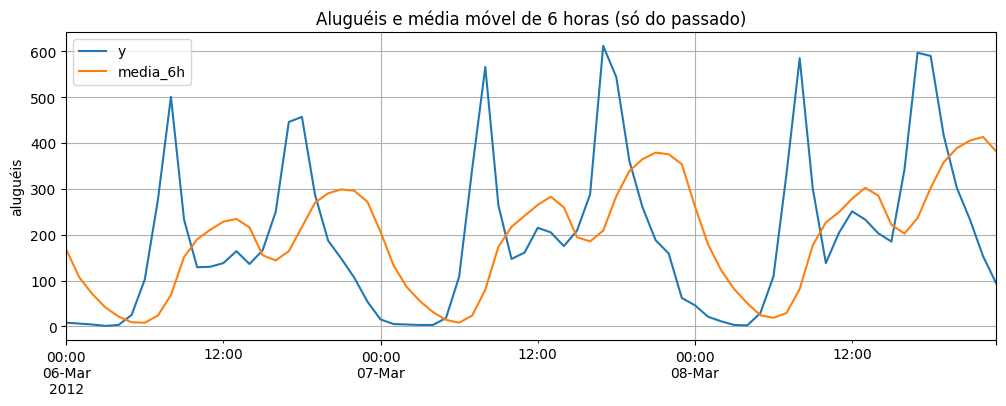

In [40]:
dados[['y', 'media_6h']].loc['2012-03-06':'2012-03-08'].plot(figsize=(12, 4), ylabel='aluguéis', grid=True, title='Aluguéis e média móvel de 6 horas (só do passado)')
plt.show()

In [42]:
dados['media_3h'] = anterior.rolling(window=3).mean()
dados['desvio_3h'] = anterior.rolling(window=3).std()

In [43]:
dados.head(10)

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h,media_3h,desvio_3h
2011-01-01 00:00:00,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-01 01:00:00,40.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-01 02:00:00,32.0,40.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-01 03:00:00,13.0,32.0,NaN,NaN,NaN,NaN,29.333333,12.220202
2011-01-01 04:00:00,1.0,13.0,NaN,NaN,NaN,NaN,28.333333,13.868429
2011-01-01 05:00:00,1.0,1.0,NaN,NaN,NaN,NaN,15.333333,15.631165
2011-01-01 06:00:00,2.0,1.0,NaN,NaN,17.166667,16.017699,5.000000,6.928203
2011-01-01 07:00:00,3.0,2.0,NaN,NaN,14.833333,17.197868,1.333333,0.577350
2011-01-01 08:00:00,8.0,3.0,NaN,NaN,8.666667,12.307179,2.000000,1.000000
2011-01-01 09:00:00,14.0,8.0,NaN,NaN,4.666667,4.844241,4.333333,3.214550


No gráfico vemos: a média móvel suaviza a série e chega com atraso, porque usa só horas passadas.

### 3.2 - Variáveis de calendário

O índice de tempo já sabe a hora, o dia da semana (`dayofweek`, de 0 a 6, a partir da segunda) e o mês. Em seguida, o perfil de aluguéis por hora e a média por dia da semana:

In [50]:
dados['hora'] = dados.index.hour
dados['dia_semana'] = dados.index.dayofweek
dados['mes'] = dados.index.month

In [49]:
dados.head(10)

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h,media_3h,desvio_3h,hora
2011-01-01 00:00:00,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2011-01-01 01:00:00,40.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,1
2011-01-01 02:00:00,32.0,40.0,NaN,NaN,NaN,NaN,NaN,NaN,2
2011-01-01 03:00:00,13.0,32.0,NaN,NaN,NaN,NaN,29.333333,12.220202,3
2011-01-01 04:00:00,1.0,13.0,NaN,NaN,NaN,NaN,28.333333,13.868429,4
2011-01-01 05:00:00,1.0,1.0,NaN,NaN,NaN,NaN,15.333333,15.631165,5
2011-01-01 06:00:00,2.0,1.0,NaN,NaN,17.166667,16.017699,5.000000,6.928203,6
2011-01-01 07:00:00,3.0,2.0,NaN,NaN,14.833333,17.197868,1.333333,0.577350,7
2011-01-01 08:00:00,8.0,3.0,NaN,NaN,8.666667,12.307179,2.000000,1.000000,8
2011-01-01 09:00:00,14.0,8.0,NaN,NaN,4.666667,4.844241,4.333333,3.214550,9


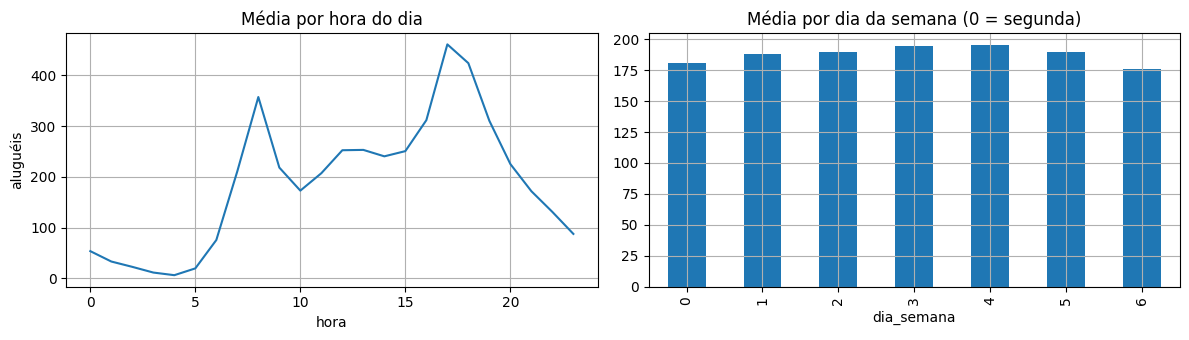

In [51]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))

dados.groupby('hora')['y'].mean().plot(ax=eixos[0], title='Média por hora do dia', ylabel='aluguéis', grid=True)

dados.groupby('dia_semana')['y'].mean().plot(kind='bar', ax=eixos[1], title='Média por dia da semana (0 = segunda)', grid=True)
plt.tight_layout()
plt.show()

In [52]:
dados.head(10)

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h,media_3h,desvio_3h,hora,dia_semana,mes
2011-01-01 00:00:00,16.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,5,1
2011-01-01 01:00:00,40.0,16.0,NaN,NaN,NaN,NaN,NaN,NaN,1,5,1
2011-01-01 02:00:00,32.0,40.0,NaN,NaN,NaN,NaN,NaN,NaN,2,5,1
2011-01-01 03:00:00,13.0,32.0,NaN,NaN,NaN,NaN,29.333333,12.220202,3,5,1
2011-01-01 04:00:00,1.0,13.0,NaN,NaN,NaN,NaN,28.333333,13.868429,4,5,1
2011-01-01 05:00:00,1.0,1.0,NaN,NaN,NaN,NaN,15.333333,15.631165,5,5,1
2011-01-01 06:00:00,2.0,1.0,NaN,NaN,17.166667,16.017699,5.000000,6.928203,6,5,1
2011-01-01 07:00:00,3.0,2.0,NaN,NaN,14.833333,17.197868,1.333333,0.577350,7,5,1
2011-01-01 08:00:00,8.0,3.0,NaN,NaN,8.666667,12.307179,2.000000,1.000000,8,5,1
2011-01-01 09:00:00,14.0,8.0,NaN,NaN,4.666667,4.844241,4.333333,3.214550,9,5,1


No gráfico vemos: o aluguel tem picos às 8 h e às 17 h e 18 h, e quase nenhum movimento de madrugada. A média por dia da semana varia pouco: no fim de semana os picos do trabalho dão lugar a um pico no meio do dia, e o que muda é o **formato** do dia, não o total. Os **feriados** também mudam esse formato, e o calendário não os conhece sozinho. O dataset marca os feriados na coluna `holiday`, e guardamos as datas em uma lista. Com `.normalize()`, cada timestamp vira a meia-noite do próprio dia, e `.isin(FERIADOS)` marca as horas dos feriados. Três horas de um feriado (28/05/2012):

In [53]:
FERIADOS = pd.to_datetime(df.loc[df['holiday'] == 1, 'dteday'].unique())
FERIADOS

<DatetimeArray>
['2011-01-17 00:00:00', '2011-02-21 00:00:00', '2011-04-15 00:00:00',
 '2011-05-30 00:00:00', '2011-07-04 00:00:00', '2011-09-05 00:00:00',
 '2011-10-10 00:00:00', '2011-11-11 00:00:00', '2011-11-24 00:00:00',
 '2011-12-26 00:00:00', '2012-01-02 00:00:00', '2012-01-16 00:00:00',
 '2012-02-20 00:00:00', '2012-04-16 00:00:00', '2012-05-28 00:00:00',
 '2012-07-04 00:00:00', '2012-09-03 00:00:00', '2012-10-08 00:00:00',
 '2012-11-12 00:00:00', '2012-11-22 00:00:00', '2012-12-25 00:00:00']
Length: 21, dtype: datetime64[ns]

In [54]:
dados['feriado'] = dados.index.normalize().isin(FERIADOS).astype(int)
dados.loc['2012-05-28 08:00':'2012-05-28 10:00', ['y', 'feriado']]

,y,feriado
2012-05-28 08:00:00,155.0,1
2012-05-28 09:00:00,263.0,1
2012-05-28 10:00:00,364.0,1


### 3.3 - Conjunto de atributos

A tabela agora tem o alvo `y` e **nove atributos**: três lags, duas estatísticas móveis e quatro variáveis de calendário. As linhas do começo, sem lag de 168 horas, ainda têm `NaN`. Com `.dropna()`, ficam só as linhas completas:

In [56]:
dados = dados.dropna()
dados.head(10)

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h,media_3h,desvio_3h,hora,dia_semana,mes,feriado
2011-01-08 00:00:00,25.0,15.0,17.0,16.0,59.833333,40.784392,30.000000,13.076697,0,5,1,0
2011-01-08 01:00:00,16.0,25.0,7.0,40.0,43.500000,28.069556,25.333333,10.503968,1,5,1,0
2011-01-08 02:00:00,16.0,16.0,1.0,32.0,30.333333,14.165686,18.666667,5.507571,2,5,1,0
2011-01-08 03:00:00,7.0,16.0,1.0,13.0,24.500000,10.747093,19.000000,5.196152,3,5,1,0
2011-01-08 04:00:00,1.0,7.0,1.0,1.0,19.166667,10.028293,13.000000,5.196152,4,5,1,0
2011-01-08 05:00:00,5.0,1.0,5.0,1.0,13.333333,8.310636,8.000000,7.549834,5,5,1,0
2011-01-08 06:00:00,2.0,5.0,34.0,2.0,11.666667,8.891944,4.333333,3.055050,6,5,1,0
2011-01-08 07:00:00,9.0,2.0,84.0,3.0,7.833333,6.675827,2.666667,2.081666,7,5,1,0
2011-01-08 08:00:00,15.0,9.0,210.0,8.0,6.666667,5.465040,5.333333,3.511885,8,5,1,0
2011-01-08 09:00:00,20.0,15.0,134.0,14.0,6.500000,5.128353,8.666667,6.506407,9,5,1,0


**Por que estes atributos e não outros.** Cada atributo vem de um padrão que vimos nos gráficos:

* `lag_1`, `lag_24` e `lag_168`: as maiores correlações sem redundância (tópico 2.3)
* `media_6h` e `desvio_6h`: resumem o passado recente (o nível e a variabilidade), que os lags isolados não mostram
* `hora`: o aluguel tem picos às 8 h e às 17 h, e quase nenhum movimento de madrugada
* `dia_semana`: no fim de semana o formato do dia muda
* `mes`: o aluguel no verão é bem maior que no inverno (a média de janeiro é cerca de metade da média do ano, e a de junho, 1,28 vez)
* `feriado`: o feriado também muda o formato do dia, e o calendário não o conhece sozinho

Ficaram de fora:

* **Outros lags** (2, 3, 48, 72 e 336): repetem a informação dos lags escolhidos. Os lags 6 e 12 têm correlação perto de zero
* **Dia do mês:** o aluguel médio varia só cerca de 10% entre os dias do mês, sem uma forma clara
* **Ano ou número da hora:** é a posição no tempo, a regressão sobre o tempo do tópico 1, que diverge no futuro
* **Clima:** só entra se for conhecido no instante da previsão (veja a nota abaixo)

> O dataset traz também o clima (`temp`, `hum`, `windspeed`). Variáveis externas entram como colunas **se forem conhecidas no instante da previsão**: a temperatura medida na hora a prever não é, mas a previsão do tempo seria. Aqui usamos só a série e o calendário. Nem todo modelo usa todos os atributos: no tópico 4, cada um usa os que fazem sentido para ele.

## 📌 4 - Modelos de ML

O modelo **não sabe** que existe tempo: ele vê apenas colunas. O tempo entra pelos atributos do tópico 3. Mas **nem todo modelo usa todos os atributos**: cada algoritmo aprende de um jeito, e um atributo que ajuda um modelo pode atrapalhar outro. Neste tópico montamos a base (treino, teste e baselines), treinamos a regressão linear, a Random Forest, o KNN e o XGBoost, cada um com os atributos que fazem sentido para ele, e no fim comparamos os quatro modelos de ML e os baselines no mesmo teste de dezembro.

### 4.1 - Treino e teste

A divisão é **cronológica**, como em qualquer previsão: o teste são as últimas `horizonte` = 744 horas (**dezembro de 2012**), que o modelo nunca viu, e o treino é todo o resto, de janeiro de 2011 a novembro de 2012. Para escolher atributos e hiperparâmetros usamos uma **validação dentro do treino**: as últimas 720 horas do treino (novembro) validam, o resto treina, e o teste fica intocado até a avaliação final. O alvo é a coluna `y`, e a lista `atributos` guarda os nomes de **todas** as colunas de atributo (cada modelo vai usar o seu subconjunto):

In [57]:
horizonte_val = 720

treino = dados.iloc[:-horizonte]
teste = dados.iloc[-horizonte:]
treino_hp = treino.iloc[:-horizonte_val]
validacao = treino.iloc[-horizonte_val:]

print('Treino:', treino.index[0], 'até', treino.index[-1], '|', len(treino), 'linhas')
print('Teste: ', teste.index[0], 'até', teste.index[-1], '|', len(teste), 'linhas')
print('Validação:', validacao.index[0], 'até', validacao.index[-1], '|', len(validacao), 'linhas')

Treino: 2011-01-08 00:00:00 até 2012-11-30 23:00:00 | 16632 linhas
Teste:  2012-12-01 00:00:00 até 2012-12-31 23:00:00 | 744 linhas
Validação: 2012-11-01 00:00:00 até 2012-11-30 23:00:00 | 720 linhas


In [58]:
atributos = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'desvio_6h', 'hora', 'dia_semana', 'mes', 'feriado']
y_treino = treino['y']
y_teste = teste['y']

print('Atributos:', atributos)

Atributos: ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'desvio_6h', 'hora', 'dia_semana', 'mes', 'feriado']


### 4.2 - Baselines

Usamos três baselines para prever 1 hora à frente. Cada um já é uma coluna de lag da tabela:

* **Naive** (`lag_1`): repete a hora anterior. Parte do princípio de que a próxima hora é parecida com a última
* **Sazonal de 24 h** (`lag_24`): repete a mesma hora de ontem. Aposta no ciclo do dia
* **Sazonal de 168 h** (`lag_168`): repete a mesma hora da semana passada. Aposta no ciclo da semana

Medimos o erro no teste com as funções `mae` e `rmse`. O dicionário `resultados` guarda o MAE e o RMSE de cada modelo no teste de dezembro, e vai receber os modelos de ML mais adiante:

In [59]:
def mae(real, previsto):
    return np.mean(np.abs(real - previsto))

def rmse(real, previsto):
    return np.sqrt(np.mean((real - previsto) ** 2))

In [60]:
baselines = {'Naive': 'lag_1', 'Sazonal 24 h': 'lag_24', 'Sazonal 168 h': 'lag_168'}
resultados = {}

for nome, coluna in baselines.items():
    resultados[nome] = [mae(y_teste, teste[coluna]), rmse(y_teste, teste[coluna])]

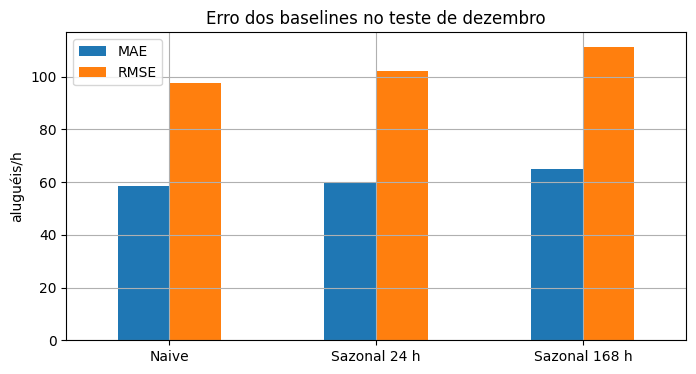

In [61]:
ax = pd.DataFrame(resultados, index=['MAE', 'RMSE']).T.plot(kind='bar', figsize=(8, 4), rot=0, ylabel='aluguéis/h', grid=True, title='Erro dos baselines no teste de dezembro')
plt.show()

O melhor baseline é o **Naive**, mas os três ficam próximos (entre 58 e 65). O aluguel depende do clima do dia, e a hora anterior carrega esse clima melhor que a mesma hora de ontem ou da semana passada. O Naive é o número a vencer.

### 4.3 - Regressão linear

A **regressão linear** prevê o valor como uma soma ponderada dos atributos: $\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots$. Cada atributo entra com um peso, e a relação com o alvo é **linear**. É isso que decide quais atributos servem a ela:

**Atributos que entram:**

* `lag_1`, `lag_24` e `lag_168`: o valor passado entra direto na soma, com um peso. É a mesma ideia do AR: o aluguel de agora é, em boa parte, proporcional ao da hora anterior, ao de ontem e ao da semana passada
* `media_6h`: resume o passado recente e suaviza o ruído dos lags. Como é quase uma combinação deles, o peso dela pode sair estranho (veremos nos coeficientes)
* `hora` e `dia_semana`, **em colunas 0/1**: um peso só para o número da hora imporia uma reta (as 20 h valeriam mais que as 8 h), mas o aluguel tem picos às 8 h e às 17 h. Com uma coluna 0/1 para cada hora e cada dia, cada valor ganha o seu próprio peso
* `feriado`: já é uma coluna 0/1, e o peso é quanto o feriado muda o aluguel

**Atributos que ficam de fora:**

* `desvio_6h`: mede quanto a série oscila, e não o nível. Uma soma ponderada não tem como usar isso, porque o efeito da oscilação depende do horário e não é proporcional
* `mes`: viraria 11 colunas 0/1 para só 22 meses de dados, com 1 ou 2 exemplos de cada mês. Os lags já carregam o nível da estação

O foco da aula são os **atributos**, e não o código de cada algoritmo. Por isso o treino e a previsão de cada modelo ficam em uma **função**, que recebe a tabela de treino, a de teste e as colunas de atributos, e devolve o modelo treinado e a previsão do teste. A `prever_linear` troca `hora` e `dia_semana` por colunas 0/1 e ajusta a escala só com o treino:

In [62]:
def prever_linear(treino, teste, colunas):
    categoricas = [c for c in colunas if c in ['hora', 'dia_semana', 'mes']]

    # uma coluna 0/1 para cada valor; drop_first tira uma coluna redundante
    X_treino = pd.get_dummies(treino[colunas], columns=categoricas, dtype=float, drop_first=True)
    X_teste = pd.get_dummies(teste[colunas], columns=categoricas, dtype=float, drop_first=True).reindex(columns=X_treino.columns, fill_value=0)

    # a escala (média e desvio) vem só do treino
    escala = StandardScaler().fit(X_treino)

    # regressão linear: um peso para cada coluna, ajustado por mínimos quadrados
    modelo = LinearRegression().fit(escala.transform(X_treino), treino['y'])
    previsao = pd.Series(modelo.predict(escala.transform(X_teste)), index=teste.index)
    return modelo, previsao, X_treino.columns

Para conferir, medimos o erro na **validação** (novembro), acrescentando um atributo por vez, na ordem da lista. A função `erro_validacao_linear` treina com os dados até outubro e devolve o MAE de novembro:

In [63]:
def erro_validacao_linear(colunas):
    _, previsao, _ = prever_linear(treino_hp, validacao, colunas)
    return mae(validacao['y'], previsao)

In [64]:
colunas = ['lag_1', 'lag_24', 'lag_168']
erros = {'só lags': erro_validacao_linear(colunas)}

for atributo in ['media_6h', 'hora', 'dia_semana', 'feriado', 'desvio_6h', 'mes']:
    colunas = colunas + [atributo]
    erros['+ ' + atributo] = erro_validacao_linear(colunas)

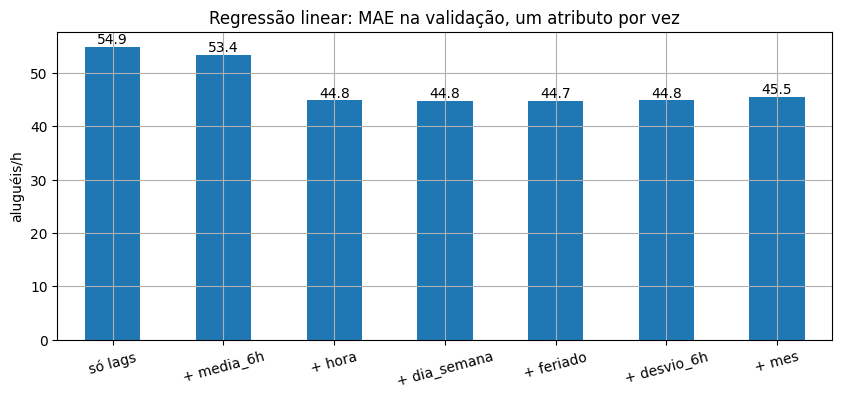

In [65]:
erro_linear_val = pd.Series(erros)
ax = erro_linear_val.plot(kind='bar', figsize=(10, 4), rot=15, ylabel='aluguéis/h', grid=True, title='Regressão linear: MAE na validação, um atributo por vez')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.show()

No gráfico vemos: a **hora** é o que mais ajuda (o erro cai de 53,4 para 44,8, com a hora em colunas 0/1). A média melhora cerca de 1,5 ponto, e o dia da semana, o feriado e o desvio mudam o erro em menos de 0,2. O mês piora (de 44,8 para 45,5). Diferenças de 1 ponto ou menos, em um mês de validação, são ruído.

Os atributos desta regressão. A função troca `hora` e `dia_semana` por colunas 0/1, uma para cada valor (o `get_dummies`). O `drop_first=True` tira uma coluna redundante de cada atributo. A tabela, nas 3 primeiras horas do teste:

In [66]:
atrib_linear = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'hora', 'dia_semana', 'feriado']
pd.get_dummies(teste[atrib_linear], columns=['hora', 'dia_semana'], dtype=float, drop_first=True).head(3)

,lag_1,lag_24,lag_168,media_6h,feriado,hora_1,hora_2,hora_3,hora_4,hora_5,...,hora_20,hora_21,hora_22,hora_23,dia_semana_1,dia_semana_2,dia_semana_3,dia_semana_4,dia_semana_5,dia_semana_6
2012-12-01 00:00:00,110.0,52.0,42.0,264.500000,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2012-12-01 01:00:00,108.0,19.0,20.0,197.666667,0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2012-12-01 02:00:00,69.0,12.0,32.0,146.333333,0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


Um lag chega a centenas, e uma coluna 0/1 vai só até 1. A escala não muda a previsão da regressão linear, mas, para os coeficientes serem comparáveis, o `StandardScaler` transforma cada coluna em $(x - \text{média}) / \text{desvio}$. A escala é ajustada **só com o treino** e apenas aplicada no teste: com a série toda, a média já conheceria o teste. Treinamos com a função `prever_linear`:

In [67]:
lin, previsao_lin, colunas_lin = prever_linear(treino, teste, atrib_linear)
resultados['Regressão linear'] = [mae(y_teste, previsao_lin), rmse(y_teste, previsao_lin)]

print('MAE da regressão linear:', round(resultados['Regressão linear'][0], 2))

MAE da regressão linear: 40.27


Uma semana do teste, previsão contra o real:

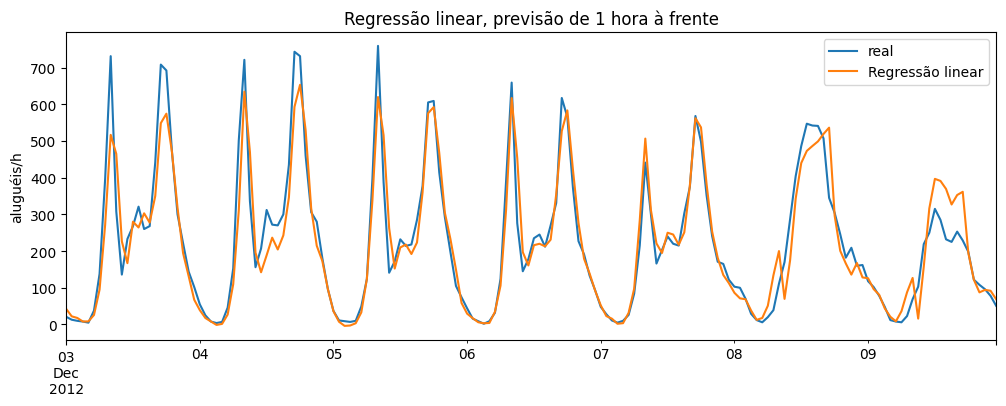

In [68]:
y_teste.loc['2012-12-03':'2012-12-09'].plot(figsize=(12, 4), label='real', ylabel='aluguéis/h', grid=True, legend=True, title='Regressão linear, previsão de 1 hora à frente')
previsao_lin.loc['2012-12-03':'2012-12-09'].plot(label='Regressão linear', color='tab:orange', legend=True)
plt.show()

No gráfico vemos: a regressão linear acompanha o formato do dia, mas subestima os picos (às 8 h e às 17 h), porque combina os atributos em linha reta e não captura as interações, como "dia útil e 8 h".

Na regressão linear, a importância de cada atributo é o seu **coeficiente**. Como as colunas foram padronizadas, os coeficientes são comparáveis: quanto maior o valor absoluto, mais a coluna move a previsão (o sinal diz se ela sobe ou desce). Mostramos todas as colunas:

In [69]:
coeficientes = pd.Series(lin.coef_, index=colunas_lin).sort_values()
coeficientes

,0
hora_9,-19.358479
media_6h,-19.235709
hora_19,-11.970329
hora_20,-6.626474
hora_10,-5.284367
hora_18,-4.127451
hora_21,-1.669244
dia_semana_6,-1.233294
feriado,-1.082260
hora_23,-0.151781


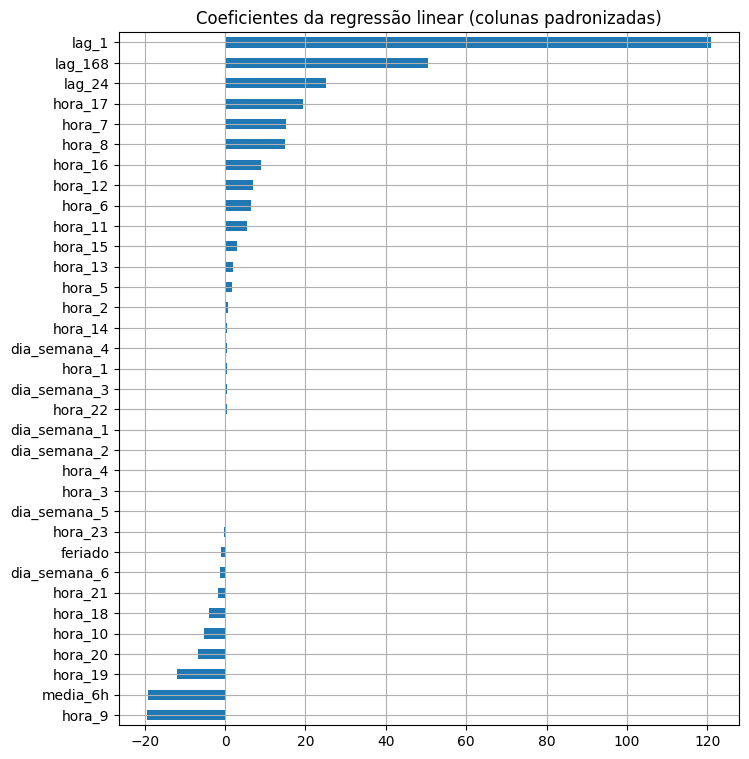

In [70]:
ax = coeficientes.plot(kind='barh', figsize=(8, 9), title='Coeficientes da regressão linear (colunas padronizadas)', grid=True)
plt.show()

No gráfico vemos: os lags dominam: `lag_1` (cerca de 121), `lag_168` (50) e `lag_24` (25). Entre as horas, 7 h, 8 h e 17 h têm os maiores pesos positivos (os picos do trabalho), e 9 h e 19 h os maiores negativos. O peso de cada hora é medido contra a hora 0, a coluna que saiu. A `media_6h` recebe peso **negativo** (cerca de -19): ela é quase uma combinação dos lags, e o modelo usa a diferença entre os dois (colinearidade). O dia da semana e o feriado pesam quase nada.

### 4.4 - Random Forest

A **Random Forest** treina várias árvores em amostras diferentes e prevê a média delas. Cada árvore divide os dados por limites (`hora < 7`, `lag_1 > 300`). Por isso:

* trata **relações não lineares e interações** sem esforço, como "dia útil e 8 h"
* **não sofre** com atributos redundantes ou pouco úteis: a árvore ignora o que não ajuda
* **não precisa de escala**, porque mudar a unidade de um atributo muda o limite e não a divisão

**Atributos que entram: os nove.**

* `lag_1`, `lag_24`, `lag_168`, `media_6h` e `desvio_6h`: a árvore divide por limites (`lag_1 > 300`), então usa o nível recente e também a oscilação, que ela combina com os outros atributos para separar momentos calmos de agitados
* `hora`, `dia_semana`, `mes` e `feriado`, **como número simples** (a hora de 0 a 23): a árvore divide por limites (`hora < 7`) e acha sozinha os picos das 8 h e das 17 h, sem precisar de colunas 0/1. O `mes` deixa a árvore separar verão de inverno

**Atributos que ficam de fora: nenhum dos nove.** A árvore ignora o que não ajuda, então um atributo a mais custa pouco. Ficam fora só o que não está na tabela:

* **ano ou número da hora:** é a posição no tempo, e a árvore só prevê dentro da faixa vista no treino (tópico 5.3)
* **clima:** não é conhecido no instante da previsão

A função `prever_rf` treina a Random Forest e prevê o teste. Os comentários explicam os argumentos:

In [75]:
def prever_rf(treino, teste, colunas, arvores=200, profundidade=None):
    modelo = RandomForestRegressor(
        # número de árvores da floresta
        n_estimators=arvores,

        # profundidade máxima de cada árvore (None: sem limite)
        max_depth=profundidade,

        # mínimo de linhas em cada folha: evita árvores que decoram o ruído
        min_samples_leaf=3,

        # semente: o resultado é o mesmo a cada execução
        random_state=42,

        # usa todos os núcleos do processador
        n_jobs=-1,
    ).fit(treino[colunas], treino['y'])

    previsao = pd.Series(modelo.predict(teste[colunas]), index=teste.index)
    return modelo, previsao

Treinamos e calculamos o erro no teste:

In [76]:
%%time

rf, previsao_rf = prever_rf(treino, teste, atributos)
resultados['Random Forest'] = [mae(y_teste, previsao_rf), rmse(y_teste, previsao_rf)]

print('MAE da Random Forest:', round(resultados['Random Forest'][0], 2))

MAE da Random Forest: 21.47
CPU times: user 28.3 s, sys: 129 ms, total: 28.4 s
Wall time: 28.5 s


A Random Forest guarda a **importância** de cada atributo: o quanto ele reduziu o erro nas árvores. Mostra **o que o modelo usou**, não a causa do aluguel:

In [78]:
importancia = pd.Series(rf.feature_importances_, index=atributos).sort_values()
importancia

,0
feriado,0.000435
mes,0.003266
dia_semana,0.008462
desvio_6h,0.010246
media_6h,0.014625
hora,0.032517
lag_24,0.043968
lag_168,0.297063
lag_1,0.589418


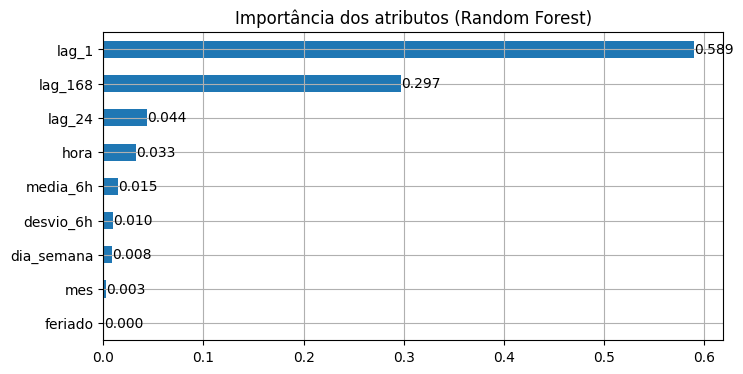

In [79]:
ax = importancia.plot(kind='barh', figsize=(8, 4), title='Importância dos atributos (Random Forest)', grid=True)
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.show()

No gráfico vemos: o `lag_1` concentra cerca de 58% da importância e o `lag_168` cerca de 30%. O `lag_24` e o calendário pesam pouco (a `hora` tem 3%), porque os lags já carregam o padrão do dia e da semana. Como a árvore ignora o que não ajuda, o `desvio_6h`, o `mes` e o `feriado` ficam perto de zero e não atrapalham, ao contrário do que acontece no KNN e na regressão linear.

### 4.5 - KNN

O **KNN** prevê o valor de uma hora pela **média dos `k` vizinhos mais parecidos** do treino, medindo a distância entre as linhas da tabela. Duas consequências:

* precisa de **escala**: sem ela, o `lag_1` (que chega a centenas) decidiria sozinho a distância, e a hora (0 a 23) quase não contaria
* prefere **poucos atributos úteis**: cada atributo entra na distância, inclusive os que não ajudam, e os vizinhos deixam de ser parecidos

**Atributos que entram:**

* `lag_1`, `lag_24` e `lag_168`: horas com lags parecidos tendem a ter aluguel parecido, e é isso que o KNN procura nos vizinhos
* `media_6h` e `desvio_6h`: a média suaviza o ruído dos lags, e o desvio separa vizinhos calmos de vizinhos agitados, que têm aluguel diferente mesmo com o mesmo nível
* `hora` e `dia_semana`, **como número**: aproximam horas próximas e dias do mesmo tipo. Pela distância, as 8 h ficam perto das 9 h e longe das 3 h, que é o que o aluguel faz
* `feriado`: separa os vizinhos de dias de feriado dos de dias comuns

**Atributos que ficam de fora:**

* `mes`: vira um número de 1 a 12, e dezembro (12) fica longe de janeiro (1), embora sejam meses vizinhos. Ele afasta linhas parecidas e ainda piora o erro (veremos no gráfico)

A função `prever_knn` usa o `make_pipeline` para guardar a escala dentro do modelo. Os comentários explicam os argumentos:

In [80]:
def prever_knn(treino, teste, colunas, k=10):
    modelo = make_pipeline(
        # escala: cada coluna com média 0 e desvio 1, para a distância não ser dominada pelos lags
        StandardScaler(),

        # número de vizinhos: a previsão é a média dos k vizinhos mais próximos do treino
        KNeighborsRegressor(n_neighbors=k),
    ).fit(treino[colunas], treino['y'])

    previsao = pd.Series(modelo.predict(teste[colunas]), index=teste.index)
    return modelo, previsao

Para conferir, o mesmo experimento do tópico 4.3, agora com o KNN (`k = 10`): o erro na **validação** (novembro), acrescentando um atributo por vez. A escala é ajustada só com os dados de treino de cada rodada:

In [81]:
def erro_validacao_knn(colunas):
    _, previsao = prever_knn(treino_hp, validacao, colunas)
    return mae(validacao['y'], previsao)

In [82]:
colunas = ['lag_1', 'lag_24', 'lag_168']
erros = {'só lags': erro_validacao_knn(colunas)}
for atributo in ['media_6h', 'hora', 'dia_semana', 'feriado', 'desvio_6h', 'mes']:
    colunas = colunas + [atributo]
    erros['+ ' + atributo] = erro_validacao_knn(colunas)

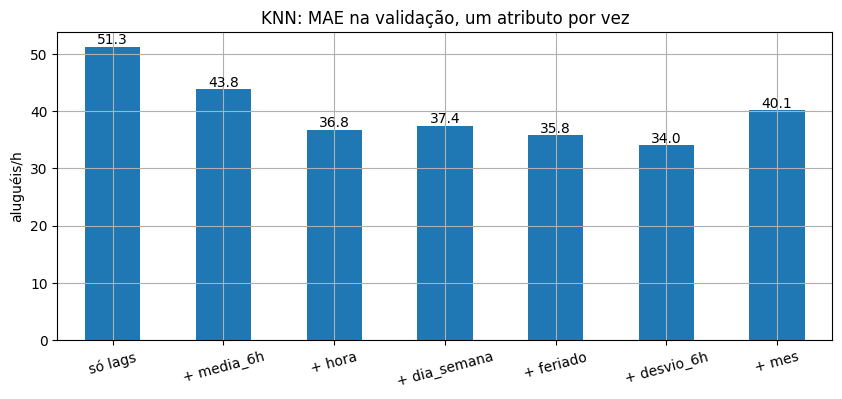

In [83]:
erro_knn_val = pd.Series(erros)
ax = erro_knn_val.plot(kind='bar', figsize=(10, 4), rot=15, ylabel='aluguéis/h', grid=True, title='KNN: MAE na validação, um atributo por vez')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.show()

No gráfico vemos: a média (o erro cai de 51,3 para 43,8) e a hora (para 36,8) são o que mais ajudam. O dia da semana, o feriado e o desvio mudam o erro em menos de 2 pontos, que em um mês de validação é ruído. O **mês piora** o erro em 6 pontos (de 34,0 para 40,1), porque dezembro e janeiro ficam distantes na escala de 1 a 12.

Os atributos do KNN e o modelo, com a função `prever_knn`. O argumento `k` é o número de vizinhos: com 10, cada previsão é a média dos 10 vizinhos mais próximos, e a escala vem só do treino:

In [85]:
atrib_knn = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'desvio_6h', 'hora', 'dia_semana', 'feriado']

In [86]:
knn, previsao_knn = prever_knn(treino, teste, atrib_knn)
resultados['KNN'] = [mae(y_teste, previsao_knn), rmse(y_teste, previsao_knn)]

print('MAE do KNN:', round(resultados['KNN'][0], 2))

MAE do KNN: 26.1


O KNN não tem importância própria. A **importância por permutação** funciona em qualquer modelo: embaralha uma coluna por vez e mede quanto o erro piora. Quanto mais piora, mais o modelo dependia daquele atributo. Para o teste não participar de nenhuma análise, treinamos o KNN só até outubro e embaralhamos as colunas da validação (novembro):

In [87]:
%%time

knn_val, _ = prever_knn(treino_hp, validacao, atrib_knn)

permutacao = permutation_importance(
    knn_val,
    validacao[atrib_knn],
    validacao['y'],
    scoring='neg_mean_absolute_error',
    n_repeats=5,
    random_state=0,
)

importancia_knn = pd.Series(permutacao.importances_mean, index=atrib_knn).sort_values()


CPU times: user 4.27 s, sys: 4.23 ms, total: 4.27 s
Wall time: 8.58 s


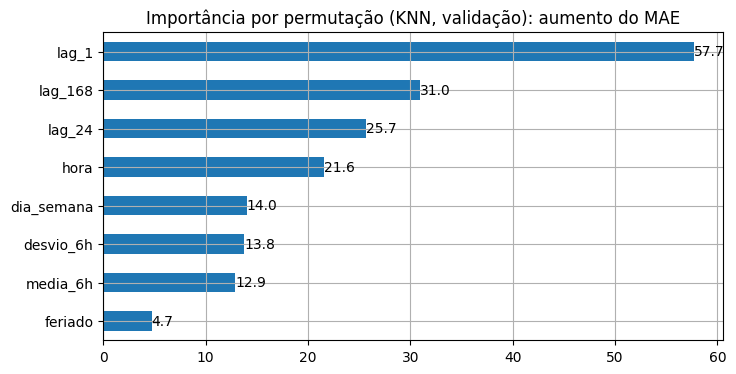

In [88]:
ax = importancia_knn.plot(kind='barh', figsize=(8, 4), title='Importância por permutação (KNN, validação): aumento do MAE', grid=True)
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.show()

No gráfico vemos: o `lag_1` é o que mais piora o erro quando embaralhado (cerca de 58 aluguéis por hora), seguido de `lag_168` (31), `lag_24` (26) e `hora` (22). O dia da semana, o desvio e a média pesam entre 13 e 14, e o `feriado` pouco (5). No KNN a `hora` pesa muito mais que na Random Forest, porque a distância precisa dela para separar as horas do dia.

### 4.6 - XGBoost

O **XGBoost** é uma implementação eficiente do **Gradient Boosting**: treina árvores **em sequência**, cada uma corrigindo o erro das anteriores. A diferença para a Random Forest é que as árvores são rasas e se complementam, em vez de votar.

**Atributos que entram: os nove.** Como a Random Forest, ele usa árvores, então os motivos são os mesmos:

* `lag_1`, `lag_24`, `lag_168`, `media_6h` e `desvio_6h`: a árvore divide por limites, e usa o nível recente e a oscilação
* `hora`, `dia_semana`, `mes` e `feriado`, como número simples: a árvore acha sozinha os limites (`hora < 7`), sem colunas 0/1 e **sem escala**

**Atributos que ficam de fora: nenhum dos nove.** Ficam fora só o ano ou número da hora (as árvores têm dificuldade para prolongar a tendência) e o clima (não é conhecido no instante da previsão).

A função `prever_xgb` treina o XGBoost e prevê o teste. Os comentários explicam os argumentos:

In [89]:
def prever_xgb(treino, teste, colunas):
    modelo = XGBRegressor(
        # número de árvores em sequência
        n_estimators=300,

        # quanto cada árvore corrige do erro das anteriores
        learning_rate=0.05,

        # profundidade de cada árvore (árvores rasas)
        max_depth=3,

        # semente
        random_state=0,

        # usa todos os núcleos do processador
        n_jobs=-1,
    ).fit(treino[colunas], treino['y'])
    previsao = pd.Series(modelo.predict(teste[colunas]), index=teste.index)
    return modelo, previsao

Treinamos e calculamos o erro no teste:

In [90]:
%%time
xgb, previsao_xgb = prever_xgb(treino, teste, atributos)
resultados['XGBoost'] = [mae(y_teste, previsao_xgb), rmse(y_teste, previsao_xgb)]
print('MAE do XGBoost:', round(resultados['XGBoost'][0], 2))

MAE do XGBoost: 25.66
CPU times: user 1.1 s, sys: 11.9 ms, total: 1.11 s
Wall time: 930 ms


A importância do XGBoost também vem do modelo:

In [91]:
importancia_xgb = pd.Series(xgb.feature_importances_, index=atributos).sort_values()


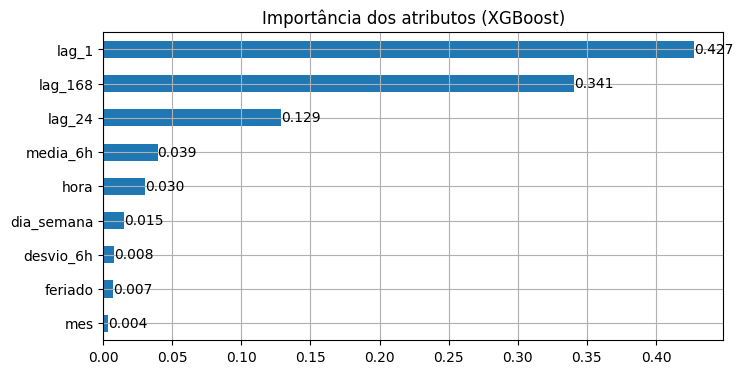

In [92]:
ax = importancia_xgb.plot(kind='barh', figsize=(8, 4), title='Importância dos atributos (XGBoost)', grid=True)
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.show()

No gráfico vemos: o `lag_1` (cerca de 43%), o `lag_168` (cerca de 34%) e o `lag_24` (cerca de 13%) concentram quase tudo. A divisão é parecida com a da Random Forest, com mais peso no `lag_24`.

### 4.7 - Comparação

Os modelos de ML e os baselines no mesmo teste de dezembro:

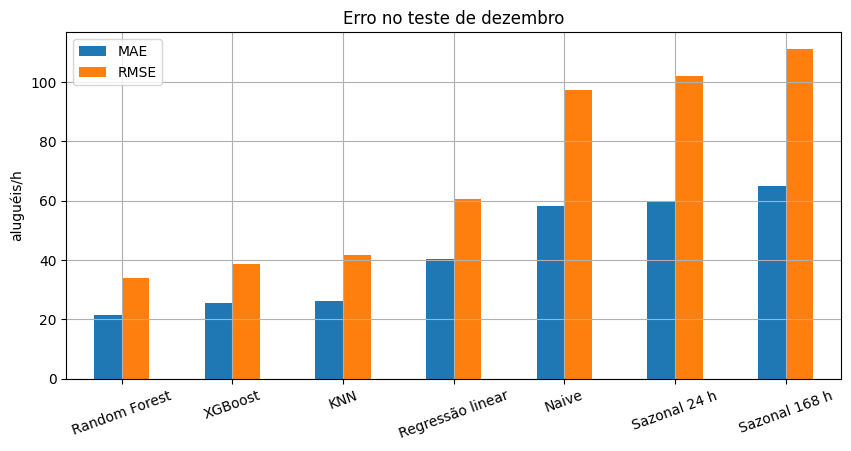

In [93]:
comparacao_ml = pd.DataFrame(resultados, index=['MAE', 'RMSE']).T.sort_values('MAE')

ax = comparacao_ml.plot(kind='bar', figsize=(10, 4.5), rot=20, ylabel='aluguéis/h', grid=True, title='Erro no teste de dezembro')
plt.show()

Três dias do teste, com o real e os quatro modelos de ML:

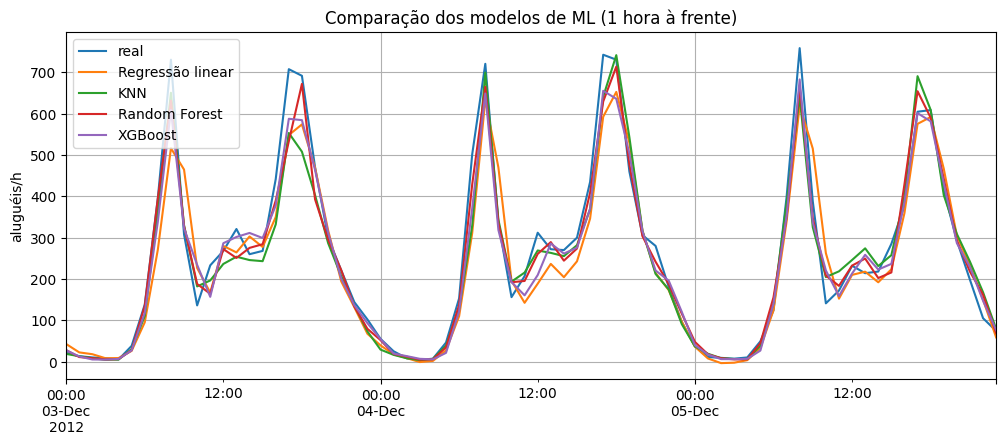

In [94]:
pd.DataFrame({
    'real': y_teste,
    'Regressão linear': previsao_lin,
    'KNN': previsao_knn,
    'Random Forest': previsao_rf,
    'XGBoost': previsao_xgb,
}).loc['2012-12-03':'2012-12-05'].plot(figsize=(12, 4.5), ylabel='aluguéis/h', grid=True, title='Comparação dos modelos de ML (1 hora à frente)')
plt.show()

No gráfico vemos: a Random Forest tem o menor erro (21,51), seguida do XGBoost (cerca de 25) e do KNN (26,10). A regressão linear (40,27) fica bem atrás: ela subestima os picos do dia, às 8 h e às 17 h. Todos os modelos de ML ficam abaixo do melhor baseline (o Naive, com 58,40). Escolher os atributos de cada modelo faz diferença: no KNN, acrescentar o mês piora o erro em 6 pontos na validação (gráfico do tópico 4.5).

## 🎯 Momento de praticar

Vamos montar o pipeline inteiro em **outro dataset**: o consumo de energia da **planta B**, uma planta industrial, medido ao longo de 2024.

1. Carregue `consumo_energia_planta_b.csv` (colunas `timestamp` e `potencia_kw`), mostre o início e **plote** a série
2. Garanta um valor por hora (`resample('h').mean()`) e preencha as lacunas com `.ffill()`
3. Construa a tabela: `lag_1`, `lag_24`, `lag_168`, `media_6h` e `desvio_6h` (só do passado) e `hora`, `dia_semana`, `mes`
4. Separe treino e teste (as últimas 744 horas, dezembro de 2024)
5. Calcule o MAE do baseline **Sazonal de 168 h**
6. Treine a **regressão linear**, o **KNN**, a **Random Forest** e o **XGBoost** (com as funções `prever_...` dos tópicos 4.3 a 4.6), cada um com os atributos que fazem sentido para ele
7. Compare o MAE dos modelos e plote uma semana do teste com o real e as quatro previsões

> **Dica:** os baselines já estão na tabela: o Sazonal de 168 h é a coluna `lag_168`. Para a regressão linear, `hora` e `dia_semana` viram colunas 0/1; para a regressão linear e o KNN, padronize os atributos com a escala do treino.

**Passo 1:** carregue o dataset e mostre o dado puro:

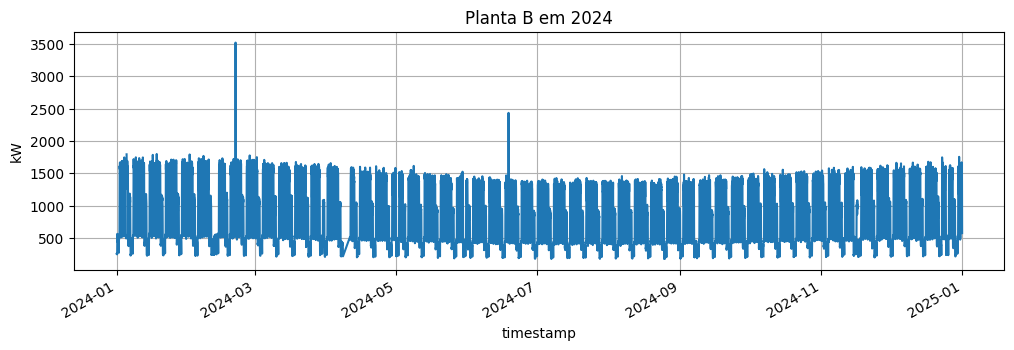

In [95]:
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
df_b['potencia_kw'].plot(figsize=(12, 3.5), title='Planta B em 2024', ylabel='kW', grid=True)
plt.show()

**Passo 2:** um valor por hora, com as lacunas preenchidas:

In [96]:
horaria_b = df_b['potencia_kw'].resample('h').mean().ffill()

print('Número de horas:', len(horaria_b))
print('Horas sem valor:', horaria_b.isna().sum())

Número de horas: 8784
Horas sem valor: 0


**Passo 3:** a tabela de atributos: primeiro os lags e o rolling, depois o calendário e, por fim, as linhas completas:

In [98]:
dados_b = pd.DataFrame({'y': horaria_b})
dados_b.head()

,y
timestamp,
2024-01-01 00:00:00,256.6
2024-01-01 01:00:00,259.6
2024-01-01 02:00:00,253.8
2024-01-01 03:00:00,247.4
2024-01-01 04:00:00,251.9


In [102]:
dados_b['lag_1'] = horaria_b.shift(1)
dados_b['lag_24'] = horaria_b.shift(24)
dados_b['lag_168'] = horaria_b.shift(168)

dados_b['media_6h'] = horaria_b.shift(1).rolling(window=6).mean()
dados_b['desvio_6h'] = horaria_b.shift(1).rolling(window=6).std()

dados_b['hora'] = dados_b.index.hour
dados_b['dia_semana'] = dados_b.index.dayofweek
dados_b['mes'] = dados_b.index.month

dados_b = dados_b.dropna()

dados_b

,y,lag_1,lag_24,lag_168,media_6h,desvio_6h,hora,dia_semana,mes
timestamp,,,,,,,,,
2024-01-08 00:00:00,534.2,254.6,232.5,256.6,382.916667,97.843618,0,0,1
2024-01-08 01:00:00,536.2,534.2,226.3,259.6,392.366667,110.699316,1,0,1
2024-01-08 02:00:00,518.6,536.2,250.5,253.8,411.100000,125.591433,2,0,1
2024-01-08 03:00:00,544.4,518.6,237.0,247.4,423.516667,132.972364,3,0,1
2024-01-08 04:00:00,523.2,544.4,247.7,251.9,441.833333,142.047452,4,0,1
...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,1536.6,1667.7,1503.8,1484.0,1502.100000,151.080164,19,1,12
2024-12-31 20:00:00,1493.1,1536.6,1453.5,1610.7,1552.533333,75.070092,20,1,12
2024-12-31 21:00:00,1546.9,1493.1,1502.2,1456.6,1531.116667,69.552381,21,1,12


In [103]:
print('Linhas completas:', len(dados_b))

Linhas completas: 8616


**Passo 4:** treino e teste cronológicos:

In [104]:
atrib_b = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'desvio_6h', 'hora', 'dia_semana', 'mes']

In [105]:
treino_b = dados_b.iloc[:-horizonte]
teste_b = dados_b.iloc[-horizonte:]

print('Linhas de treino:', len(treino_b))
print('Linhas de teste:', len(teste_b))

Linhas de treino: 7872
Linhas de teste: 744


**Passo 5:** o baseline:

In [107]:
print('MAE do Sazonal 1 h:', round(mae(teste_b['y'], teste_b['lag_1']), 2))
print('MAE do Sazonal 24 h:', round(mae(teste_b['y'], teste_b['lag_24']), 2))
print('MAE do Sazonal 168 h:', round(mae(teste_b['y'], teste_b['lag_168']), 2))

MAE do Sazonal 1 h: 123.4
MAE do Sazonal 24 h: 319.17
MAE do Sazonal 168 h: 65.22


**Passo 6:** os quatro modelos, cada um com os seus atributos. A **regressão linear**, com a hora e o dia da semana em colunas 0/1:

In [108]:
atrib_lin_b = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'hora', 'dia_semana']

lin_b, prev_lin_b, _ = prever_linear(treino_b, teste_b, atrib_lin_b)

print('MAE da regressão linear:', round(mae(teste_b['y'], prev_lin_b), 2))

MAE da regressão linear: 65.51


O **KNN**, com poucos atributos:

In [109]:
atrib_knn_b = ['lag_1', 'lag_24', 'lag_168', 'media_6h', 'desvio_6h', 'hora', 'dia_semana']

knn_b, prev_knn_b = prever_knn(treino_b, teste_b, atrib_knn_b)

print('MAE do KNN:', round(mae(teste_b['y'], prev_knn_b), 2))

MAE do KNN: 39.29


A **Random Forest** e o **XGBoost**, com todos os atributos e sem escala:

In [110]:
%%time

rf_b, prev_rf_b = prever_rf(treino_b, teste_b, atrib_b)
xgb_b, prev_xgb_b = prever_xgb(treino_b, teste_b, atrib_b)

print('MAE da Random Forest:', round(mae(teste_b['y'], prev_rf_b), 2))
print('MAE do XGBoost:', round(mae(teste_b['y'], prev_xgb_b), 2))

MAE da Random Forest: 38.11
MAE do XGBoost: 39.06
CPU times: user 17 s, sys: 51.8 ms, total: 17 s
Wall time: 16 s


**Passo 7:** o MAE dos modelos, com o baseline como referência:

In [111]:
previsoes_b = {
    'Regressão linear': prev_lin_b,
    'KNN': prev_knn_b,
    'Random Forest': prev_rf_b,
    'XGBoost': prev_xgb_b,
}

In [112]:
erros_b = pd.Series({nome: mae(teste_b['y'], prev) for nome, prev in previsoes_b.items()})
erros_b['Sazonal 168 h'] = mae(teste_b['y'], teste_b['lag_168'])

erros_b

,0
Regressão linear,65.509646
KNN,39.293017
Random Forest,38.106754
XGBoost,39.057839
Sazonal 168 h,65.222043


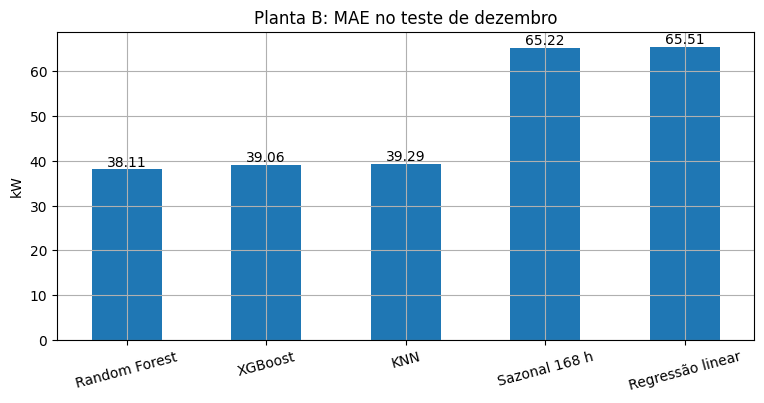

In [113]:
ax = erros_b.sort_values().plot(kind='bar', figsize=(9, 4), rot=15, ylabel='kW', grid=True, title='Planta B: MAE no teste de dezembro')
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.show()

**Conclusão:** na planta B, o baseline Sazonal de 168 h tem MAE de 65,22 kW. A Random Forest (38,06), o XGBoost (cerca de 39) e o KNN (39,29) reduzem o erro em cerca de 40% a 42%, e a regressão linear (65,51) fica igual ao baseline. Mais uma vez, os modelos que não exigem uma relação linear vencem o baseline também em outra série.

## 📌 5 - Comparação com modelos estatísticos

Os modelos estatísticos (suavização, ARIMA e SARIMA) usam **só a própria série**, funcionam bem com **poucas observações** e têm tendência e sazonalidade explícitas, com intervalos de previsão. Os modelos de ML (Random Forest, XGBoost) usam **a série e outras colunas**, funcionam bem com **muitas observações** e capturam relações não lineares e variáveis externas.

Para comparar de forma justa com o ML, que prevê 1 hora à frente com os valores reais anteriores, o SARIMA também precisa prever **1 passo à frente** no período de teste.

### 5.1 - SARIMA

Recortamos as últimas 4 semanas do treino (672 horas) e ajustamos nelas um SARIMA $(1,0,0)(1,1,0)_{24}$ (sazonalidade diária):

In [117]:
%%time

ultimas = horaria.iloc[-horizonte - 672:-horizonte]
sarima = SARIMAX(
    # série de treino
    ultimas,

    # (p, d, q): um termo autorregressivo
    order=(1, 0, 1),

    # (P, D, Q, m): sazonalidade de 24 horas, com uma diferença sazonal
    seasonal_order=(1, 1, 1, 24),
).fit(disp=False)

sarima.params

CPU times: user 15.3 s, sys: 556 ms, total: 15.9 s
Wall time: 15.3 s


,0
ar.L1,0.603890
ma.L1,0.428634
ar.S.L24,0.360043
ma.S.L24,-0.997777
sigma2,3756.450102


Com os parâmetros fixos, `.apply` aplica o modelo a dados **novos** (incluindo dezembro) sem reajustar. A previsão 1 passo à frente de cada hora de dezembro sai de `.get_prediction`:

In [118]:
sarima_total = sarima.apply(horaria.iloc[-horizonte - 672:])

previsao_sarima = sarima_total.get_prediction(
    # primeira hora do teste (01/12 às 00h)
    start=teste.index[0],
).predicted_mean

resultados['SARIMA'] = [mae(y_teste, previsao_sarima), rmse(y_teste, previsao_sarima)]
print('MAE do SARIMA:', round(resultados['SARIMA'][0], 2))

MAE do SARIMA: 36.89


### 5.2 - Comparação final

Todos os modelos no mesmo teste (dezembro), com a mesma métrica:

In [119]:
comparacao = pd.DataFrame(resultados, index=['MAE', 'RMSE']).T.sort_values('MAE')
comparacao.round(2)

,MAE,RMSE
Random Forest,21.47,34.07
XGBoost,25.66,38.76
KNN,26.10,41.61
SARIMA,36.89,57.93
Regressão linear,40.27,60.63
Naive,58.40,97.48
Sazonal 24 h,60.01,102.15
Sazonal 168 h,65.13,111.33


O **MAPE** (erro percentual absoluto médio) mede o erro em relação ao valor real: $\text{MAPE} = \frac{100}{n} \sum \frac{|y_t - \hat{y}_t|}{y_t}$. A função `mape`, a previsão de cada modelo e a tabela com o MAPE:

In [120]:
def mape(real, previsto):
    return np.mean(np.abs((real - previsto) / real)) * 100

In [121]:
previsoes = {
    'Naive': teste['lag_1'],
    'Sazonal 24 h': teste['lag_24'],
    'Sazonal 168 h': teste['lag_168'],
    'Regressão linear': previsao_lin,
    'KNN': previsao_knn,
    'Random Forest': previsao_rf,
    'XGBoost': previsao_xgb,
    'SARIMA': previsao_sarima,
}
comparacao['MAPE (%)'] = pd.Series({nome: mape(y_teste, prev) for nome, prev in previsoes.items()})
comparacao.round(2)

,MAE,RMSE,MAPE (%)
Random Forest,21.47,34.07,30.73
XGBoost,25.66,38.76,46.72
KNN,26.10,41.61,43.48
SARIMA,36.89,57.93,67.91
Regressão linear,40.27,60.63,77.19
Naive,58.40,97.48,54.17
Sazonal 24 h,60.01,102.15,87.09
Sazonal 168 h,65.13,111.33,128.13


O MAPE mantém a Random Forest em primeiro (30,7%), mas **muda a ordem** de outros modelos. No MAE o SARIMA vence o Naive, e no MAPE o Naive (54,2%) fica à frente dele (57,2%). A regressão linear é a mais afetada: tem MAE próximo do SARIMA (40,27 contra 39,08), mas MAPE de 77,2%. Os percentuais são altos porque o aluguel de madrugada é pequeno (33 horas do teste têm menos de 5 aluguéis), e um erro de 3 aluguéis sobre um valor real de 1 vale 300%. Em séries com valores perto de zero, o MAPE exagera, e o MAE é mais confiável.

Três dias do teste, com o real, o SARIMA e os dois melhores modelos de ML:

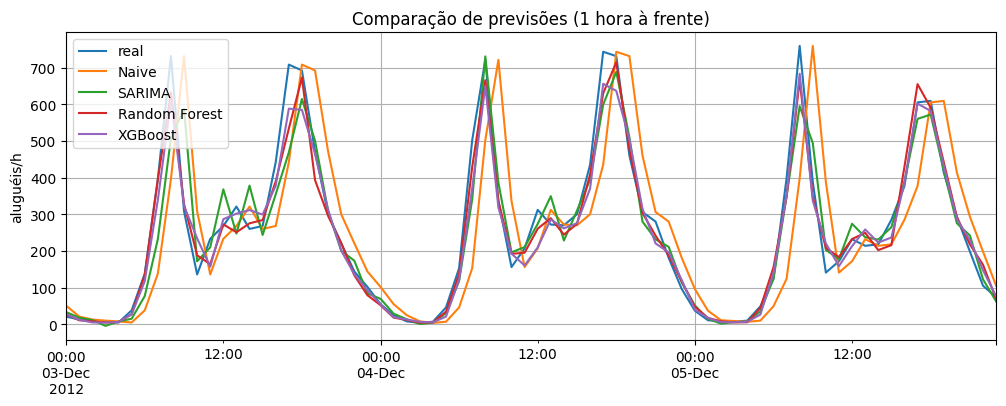

In [122]:
pd.DataFrame({
    'real': y_teste,
    'Naive': teste['lag_1'],
    'SARIMA': previsao_sarima,
    'Random Forest': previsao_rf,
    'XGBoost': previsao_xgb,
}).loc['2012-12-03':'2012-12-05'].plot(figsize=(12, 4), ylabel='aluguéis/h', grid=True, title='Comparação de previsões (1 hora à frente)')
plt.show()

O vencedor depende da série: **compare** sempre, com o mesmo teste. Aqui a Random Forest (21,51) vence o SARIMA (39,08), que usa só a série e a sazonalidade diária e não conhece o ciclo da semana. O SARIMA, por sua vez, vence os baselines e fica próximo da regressão linear (40,27). Uma ressalva: o SARIMA foi ajustado só com as últimas 4 semanas do treino, e os modelos de ML usaram quase dois anos, então os históricos de treino são diferentes.

### 5.3 - Extrapolação de tendência

A Random Forest prevê a **média de exemplos já vistos** no treino. Por isso a previsão fica **dentro da faixa do treino** e nunca passa do máximo que o modelo viu. O KNN tem o mesmo limite, porque só repete vizinhos do treino. O XGBoost soma as contribuições das árvores e, em tese, pode passar da faixa, mas também tem dificuldade para prolongar uma tendência que não viu. Com **tendência**, isso vira problema: o valor futuro passa do máximo do treino. A causa está em como a árvore prevê, e não na falta de dados. A **regressão linear** não tem esse limite, porque continua a reta.

> **Dataset:** a série diária de aluguéis do tópico 1.2, que cresce de 2011 para 2012. Treino em 2011 e teste em 2012, o ano todo.

Usamos a função `prever_rf`, a mesma Random Forest do tópico 4.4. A tabela tem os lags de 1 e de 7 dias, a média dos 7 dias anteriores e o dia da semana:

Agora o mesmo problema prevendo a **variação** em relação ao ciclo anterior (7 dias atrás). O alvo é $y_t - y_{t-7}$, os atributos são as variações recentes, e a previsão do nível soma de volta o valor de 7 dias atrás:

Por fim, a regressão linear prevendo o nível, só com os lags e a média (o dia da semana pediria colunas 0/1):

No gráfico vemos: a Random Forest que prevê o nível (vermelho) fica abaixo do máximo do treino (azul tracejado), e o erro **cresce** no teste (MAE de 1.393 aluguéis por dia), porque a tendência leva o aluguel para valores que ela nunca viu. Prevendo a **variação** (verde), a previsão acompanha a série e o MAE cai para 981. A regressão linear (laranja) passa do máximo do treino e acompanha a alta, com MAE de 820, o menor dos três. Outra saída é **remover a tendência** antes e prever o resto. O XGBoost também tem dificuldade para acompanhar a alta: ele pode passar da faixa do treino, mas nesta série ficou abaixo do máximo, como a Random Forest.

## 📌 6 - Limitações dos modelos

Nenhum modelo serve para tudo: cada um tem limitações, e conhecê-las ajuda a escolher o modelo e a desconfiar de um resultado. Por modelo:

**Regressão linear**

* só captura relações **lineares**: os picos às 8 h e às 17 h ficam subestimados (tópico 4.7), e o calendário precisa de colunas 0/1
* sofre com atributos **correlacionados** (colinearidade): a `media_6h`, quase uma combinação dos lags, recebe um peso negativo (tópico 4.3)
* é sensível a **valores extremos** e pode ter **coeficientes instáveis** quando os atributos são muito correlacionados

**KNN**

* precisa de **escala**, porque a distância é dominada pelas colunas de números grandes
* sofre com atributos que não ajudam: cada um entra na distância, e o `mes` piorou o erro em 6 pontos (tópico 4.5)
* guarda **todo o treino** e compara cada previsão com ele, então fica lento com muitos dados
* só repete vizinhos do treino, então **não extrapola**

**Random Forest**

* prevê a média de exemplos do treino, então fica **dentro da faixa vista** e não extrapola tendência
* é difícil de **interpretar**: são centenas de árvores, e só a importância dos atributos resume o que ela usou

**XGBoost**

* também tem **dificuldade para extrapolar**: soma as contribuições das árvores e, em tese, pode passar da faixa do treino, mas não prolonga bem uma tendência que não viu
* tem **mais hiperparâmetros** e é mais sensível a eles que a Random Forest, e as árvores em sequência podem decorar o ruído

A limitação mais séria em séries com tendência é a **extrapolação**, vista no tópico 5.3.

## 🎯 Momento de praticar

Dois exercícios na série de aluguéis, com os atributos dos tópicos 3 e 4.

**Exercício 1 - Erro por hora do dia**

1. Calcule o erro absoluto de cada hora do teste, para a Random Forest e para o baseline Naive
2. Agrupe os erros pela hora do dia e calcule a média de cada hora
3. Plote os dois erros por hora e veja em que horas o modelo mais erra

**Exercício 2 - Comparativo com ajuste**

1. Valide **só dentro do treino**: treine até 31/10 e valide em novembro o `k` do KNN (5, 10 e 20) e o `max_depth` da Random Forest (4, 8 e 16)
2. Escolha o melhor valor de cada um
3. Treine o KNN e a Random Forest ajustados com todo o treino e avalie no teste de dezembro
4. Registre o erro de validação de cada valor e compare, em um gráfico, os modelos de ML do teste, com e sem ajuste

> **Dica do exercício 2:** o teste de dezembro só entra no passo 3, depois da escolha. Escolher os hiperparâmetros olhando o teste contamina a avaliação. O KNN usa os atributos do tópico 4.5.

**Passos 1 a 3:** o erro absoluto de cada hora do teste, a média do erro de cada hora do dia e o gráfico:

#### Exercício 2 - Comparativo com ajuste

**Passo 1:** a validação fica **dentro do treino** (`treino_hp` e `validacao`, do tópico 4.1): treinamos até outubro e validamos em novembro. Primeiro o `k` do KNN, com a função `prever_knn`:

Agora o `max_depth` da Random Forest:

**Passo 2:** o melhor valor de cada um é a primeira linha do registro:

**Passo 3:** treinamos o KNN e a Random Forest ajustados com todo o treino e avaliamos no teste de dezembro:

**Passo 4:** o MAE no teste dos modelos de ML, com e sem ajuste:

**Conclusão:**
* **Exercício 1:** o Naive erra mais às 8 h e às 9 h (170 e 181 aluguéis por hora) e às 17 h (139), quando o aluguel muda rápido. A Random Forest reduz o erro em quase todas as horas e perde para o Naive só entre 13 h e 15 h, quando o aluguel varia pouco. O maior erro dela fica às 17 h (71).
* **Exercício 2:** validando em novembro, o melhor `k` do KNN é 10 (MAE de 34,03, contra 34,36 com 5 e 35,35 com 20) e o melhor `max_depth` da Random Forest é 16 (29,83, contra 36,48 com 8 e 54,79 com 4: a árvore rasa não captura o padrão). No teste de dezembro, o KNN ajustado repete o `k=10` e dá o mesmo MAE do tópico 4.5 (26,10), e a Random Forest ajustada tem 21,49, contra 21,51 da padrão: o ajuste ajuda pouco, porque os atributos já fazem quase todo o trabalho. A ordem dos modelos não muda: Random Forest, XGBoost, KNN e regressão linear.

## 📌 Conclusão

O pipeline completo de previsão, em 7 etapas:

1. **Série:** dados em ordem, com todos os períodos (`asfreq` e `ffill`)
2. **Atributos:** lags, estatísticas móveis e calendário, só do passado
3. **Divisão cronológica:** treino e teste
4. **Modelo:** regressão linear, KNN, Random Forest ou XGBoost, com os atributos que fazem sentido para ele
5. **Avaliação:** MAE, RMSE e baseline no teste
6. **Comparação:** com o baseline e com os modelos estatísticos
7. **Registro:** guarde atributos, hiperparâmetros e métricas de cada rodada

* O Machine Learning espera uma **tabela**: a série vira atributos (lags, médias móveis, calendário) e alvo, e o tempo entra pelos atributos, não pela data. A regressão sobre o tempo decora o treino e erra o futuro
* **Cada modelo usa os atributos que fazem sentido para ele**: a regressão linear pede relações lineares e colunas 0/1 para o calendário, o KNN pede poucos atributos padronizados, e as árvores (Random Forest e XGBoost) aceitam todos, sem escala
* A importância dos atributos mostra **o que cada modelo usou**: coeficientes na regressão linear, importância das árvores e importância por permutação no KNN
* **Random Forest** e **XGBoost** ganham dos baselines. A Random Forest prevê dentro da faixa vista no treino, e o XGBoost também tem dificuldade para prolongar uma tendência. Com tendência, preveja a variação ou remova a tendência. Os lags vêm do ciclo sazonal da série
* Os **hiperparâmetros** se ajustam só dentro do treino, e os resultados de cada rodada ficam registrados
* Todo modelo é comparado com o **baseline** e com os modelos estatísticos, no mesmo teste
* A previsão é de **1 hora à frente**, e os lags usam os valores reais anteriores, inclusive em dezembro: é o uso com o histórico atualizado a cada hora. Prever o mês inteiro de uma vez, sem esses valores, é um problema mais difícil, e os erros seriam maiores